# Class-Conditional DDPM on CIFAR-10

## From-scratch diffusion model with U-Net, timestep conditioning, class conditioning, self-attention, EMA, and classifier-free guidance

This notebook documents a **class-conditional Denoising Diffusion Probabilistic Model (DDPM)** implemented from scratch in PyTorch and trained on **CIFAR-10 (32×32 RGB images)**.

The goal of this project is not to reproduce a state-of-the-art diffusion system. The goal is to make the complete diffusion pipeline understandable and inspectable:

- forward diffusion and noise injection
- sinusoidal timestep embeddings
- one-hot class conditioning
- residual blocks
- multi-resolution self-attention
- U-Net encoder/decoder with skip connections
- classifier-free guidance (CFG)
- exponential moving average (EMA)
- deterministic evaluation with fixed noise
- mixed class conditioning
- training/resource logging
- checkpointing and reproducible comparisons

### Final model at a glance

| Component | Choice |
|---|---|
| Dataset | CIFAR-10 |
| Image size | 32 × 32 × 3 |
| Diffusion steps | 1000 |
| Noise schedule | Linear, β = 1e-4 → 0.02 |
| Architecture | Compact U-Net |
| Parameters | 6,767,683 |
| Class conditioning | 11-dimensional one-hot vector |
| Classes | 10 CIFAR-10 classes + 1 null class |
| Timestep embedding | Sinusoidal, 64 → 256 |
| Attention | 32×32, 16×16, 8×8 |
| Objective | Noise prediction MSE |
| EMA | Decay 0.999 |
| CFG | Used during sampling |
| Training augmentation | Random horizontal flip |
| Output | 32×32 RGB image |
| Executed training | 30,000 optimizer steps across v65 and v66 (15,000 each) |

> **Important:** The notebook below is the actual executed experiment. Existing code cells and their captured outputs are preserved. The added sections explain what each part is doing without changing the experiment itself.

# Utils

In [1]:
print("STARTED", flush=True)

STARTED


In [2]:
from IPython import get_ipython
get_ipython().ast_node_interactivity = "all"

In [3]:
import shutil

src = "/kaggle/input/models/anjumulazim/ddpm-2/pytorch/default/21/diffusion_best_15.pt"
dst = "/kaggle/working/diffusion_best.pt"

shutil.copy2(src, dst)
print("Copied successfully!")

'/kaggle/working/diffusion_best.pt'

Copied successfully!


In [4]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Number of GPUs: ",torch.cuda.device_count())


def time_embedding(t, dim):
    
    half = dim//2
    if half==1:
        frequencies = torch.ones(1, device=t.device)
    else:
        frequencies = torch.exp(
            -torch.log((torch.tensor(10000.0)))
            *(torch.arange(half, device=t.device))/(half-1)
        )

    angles = t[:, None]*frequencies[None, :]

    # print(t.shape)
    # print(frequencies.shape)
    # print(angles.shape)

    sin = torch.sin(angles)
    cos = torch.cos(angles)
    embedding = torch.cat([sin, cos], dim=1)

    return embedding.to(device)

Device: cuda
GPU: Tesla T4
Number of GPUs:  2


# Dataset

## CIFAR-10

CIFAR-10 contains 60,000 color images of size **32×32**, divided into 10 semantic classes:

`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`

The training pipeline applies:

1. `RandomHorizontalFlip()` for simple augmentation.
2. `ToTensor()` to convert images to tensors.
3. normalization from `[0, 1]` to approximately `[-1, 1]`.

The model therefore learns to predict noise in the normalized image space.

### Why CIFAR-10?

CIFAR-10 is small enough to make a diffusion model practical to train while still containing meaningful object structure. At 32×32, the model has to learn useful global shapes and local textures under a very constrained resolution.

# Dataset

torch.Size([128, 3, 32, 32])
torch.Size([128])


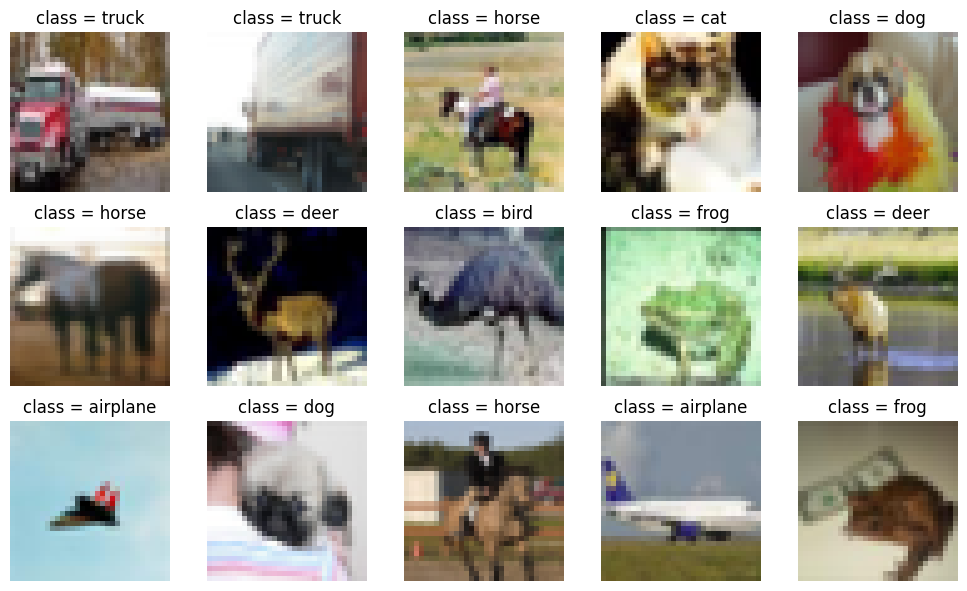

In [5]:
class CIFAR10Data:
    def __init__(self, batch_size=128, source="official"):

        self.class_names = [
            "airplane", "automobile", "bird", "cat", "deer",
            "dog", "frog", "horse", "ship", "truck"
        ]

        transform = transforms.Compose([
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

        root = "./data"

        if source == "huggingface":
            import os, urllib.request, tarfile
            archive = os.path.join(root, "cifar-10-python.tar.gz")
            folder = os.path.join(root, "cifar-10-batches-py")
            os.makedirs(root, exist_ok=True)

            if not os.path.exists(folder):
                url = "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/resolve/main/cifar-10-python.tar.gz"
                print("Downloading CIFAR-10 from Hugging Face...")
                urllib.request.urlretrieve(url, archive)
                with tarfile.open(archive, "r:gz") as tar:
                    tar.extractall(root, filter="data")

            download = False

        elif source == "official":
            download = True

        else:
            raise ValueError("source must be 'official' or 'huggingface'")

        self.dataset = datasets.CIFAR10(
            root=root,
            train=True,
            download=download,
            transform=transform
        )

        self.loader = DataLoader(self.dataset, batch_size=batch_size, shuffle=True)

    def plot_batch(self, images=None, labels=None):

        if images is None or labels is None:
            images, labels = next(iter(self.loader))

        fig, axes = plt.subplots(3, 5, figsize=(10, 6))

        for i, ax in enumerate(axes.flat):
            img = images[i].permute(1, 2, 0)
            img = (img + 1) / 2

            _ = ax.imshow(img)
            _ = ax.set_title(f"class = {self.class_names[labels[i].item()]}")
            _ = ax.axis("off")

        plt.tight_layout()
        plt.show()
        plt.close(fig)


# =============================================================
# Use
# =============================================================

data = CIFAR10Data(batch_size=128, source="huggingface")

images, labels = next(
    iter(data.loader)
)

print(images.shape)
print(labels.shape)

data.plot_batch(images, labels)

# Model

The denoiser is a compact **U-Net**. At every stage, the network receives information about:

- **where we are in the diffusion process** through the timestep embedding `t`
- **what class to generate** through the class embedding `y`

The model predicts the noise that was added to a noisy image.

### High-level data flow

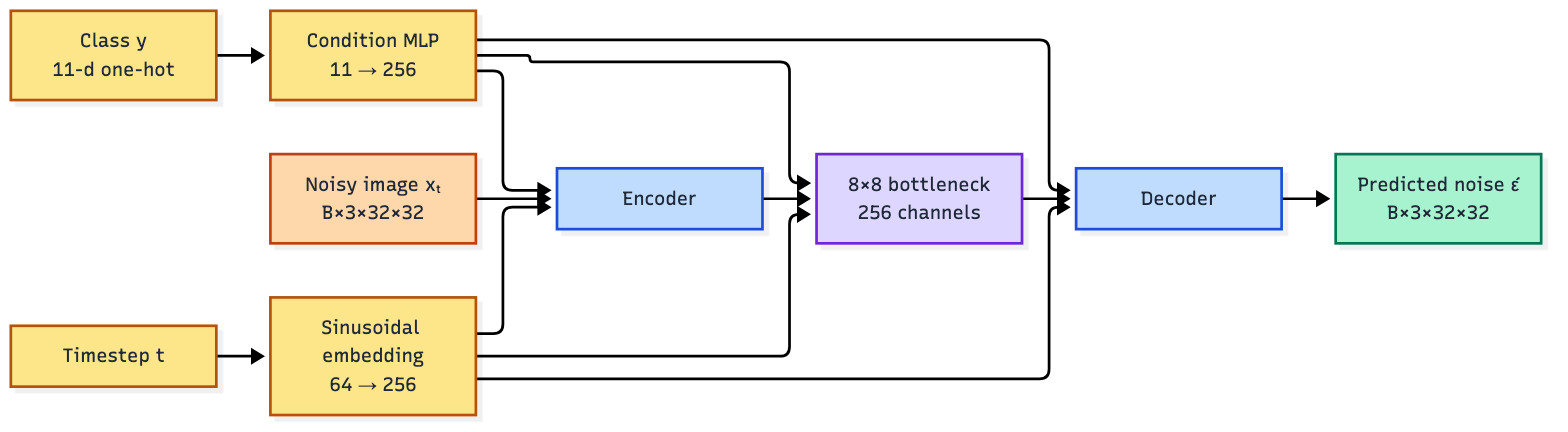

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart LR
    X["Noisy image xₜ<br/>B×3×32×32"] --> E["Encoder"]
    E --> B["8×8 bottleneck<br/>256 channels"]
    B --> D["Decoder"]
    D --> O["Predicted noise ε̂<br/>B×3×32×32"]
    T["Timestep t"] --> TE["Sinusoidal embedding<br/>64 → 256"]
    Y["Class y<br/>11-d one-hot"] --> CE["Condition MLP<br/>11 → 256"]
    TE --> E
    TE --> B
    TE --> D
    CE --> E
    CE --> B
    CE --> D
    classDef image fill:#fed7aa,stroke:#c2410c,color:#1f2937
    classDef encoder fill:#bfdbfe,stroke:#1d4ed8,color:#1f2937
    classDef bottleneck fill:#ddd6fe,stroke:#6d28d9,color:#1f2937
    classDef output fill:#a7f3d0,stroke:#047857,color:#1f2937
    classDef condition fill:#fde68a,stroke:#b45309,color:#1f2937
    class X image
    class E,D encoder
    class B bottleneck
    class O output
    class T,TE,Y,CE condition
```

</details>

The same timestep and class information is injected into residual blocks and attention blocks throughout the network.

# Model

## TinyUNet: Residual Blocks + Multi-Resolution Attention

The architecture deliberately stays compact enough to train on a practical setup while still containing the important ideas used by larger diffusion systems.

### Spatial resolution and channel progression

| Stage | Spatial size | Channels |
|---|---:|---:|
| Input | 32×32 | 3 |
| Encoder level 1 | 32×32 | 64 |
| Encoder level 2 | 16×16 | 128 |
| Bottleneck | 8×8 | 256 |
| Decoder level 1 | 16×16 | 128 |
| Decoder level 2 | 32×32 | 64 |
| Output | 32×32 | 3 |

The two downsampling layers reduce spatial resolution while increasing feature channels. The two transpose-convolution layers reverse this process.

### Why a U-Net?

Diffusion denoising needs both:

- **global information**, such as the overall object structure
- **local information**, such as edges and textures

Skip connections allow high-resolution encoder features to reach the decoder directly.

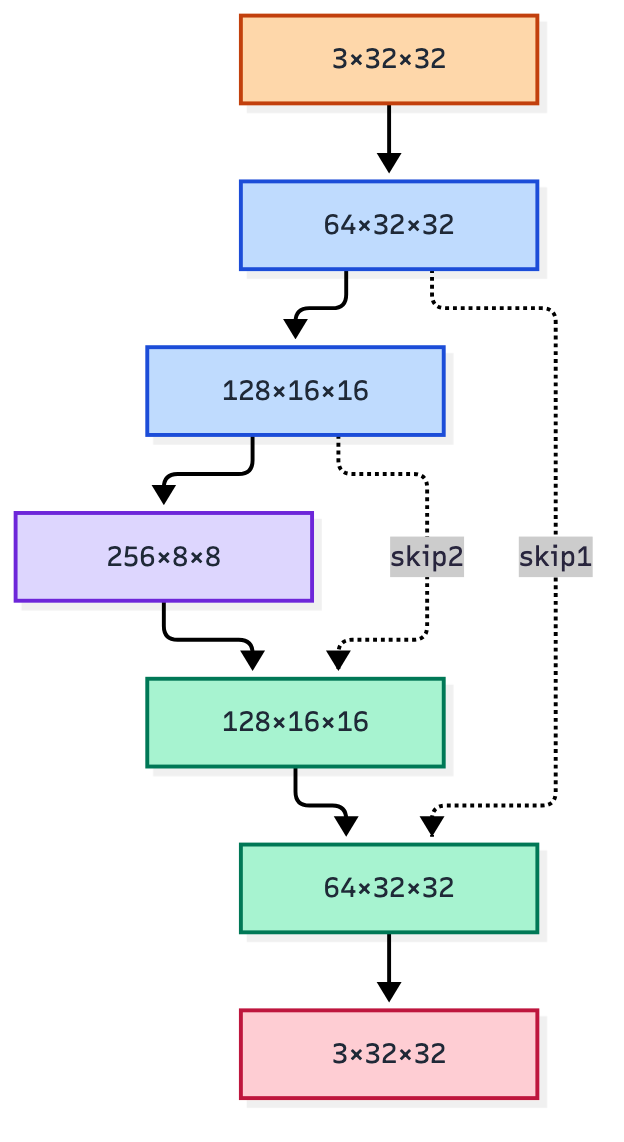

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TD
    A["3×32×32"] --> B["64×32×32"]
    B --> C["128×16×16"]
    C --> D["256×8×8"]
    D --> E["128×16×16"]
    E --> F["64×32×32"]
    F --> G["3×32×32"]
    C -. "skip2" .-> E
    B -. "skip1" .-> F
    classDef input fill:#fed7aa,stroke:#c2410c,color:#1f2937
    classDef encoder fill:#bfdbfe,stroke:#1d4ed8,color:#1f2937
    classDef bottleneck fill:#ddd6fe,stroke:#6d28d9,color:#1f2937
    classDef decoder fill:#a7f3d0,stroke:#047857,color:#1f2937
    classDef output fill:#fecdd3,stroke:#be123c,color:#1f2937
    class A input
    class B,C encoder
    class D bottleneck
    class E,F decoder
    class G output
```

</details>

The actual tensor concatenations are:

- `128 + 128 = 256` channels at 16×16
- `64 + 64 = 128` channels at 32×32

## TinyUNet: With Residual Block

In [6]:
import torch.nn.functional as F

class ConditionMLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, output_dim),
            nn.SiLU(),
            nn.Linear(output_dim, output_dim)
        )
        
    def forward(self, x):
        return self.net(x)

class SelfAttention(nn.Module):

    def __init__(self, channels, time_dim=256, label_dim=256):
        super().__init__()

        self.q = nn.Linear(channels, channels) # Query
        self.k = nn.Linear(channels, channels) # Key
        self.v = nn.Linear(channels, channels) # Value

        self.out = nn.Linear(channels, channels)

        self.time_proj = nn.Linear(
            time_dim, channels
        )

        self.label_proj = nn.Linear(
            label_dim, channels
        )

    def forward(self, x, t_emb, label_emb):

        # x: [B, C, H, W]
        B, C, H, W = x.shape

        # Add timestep conditioning
        # [B,256] -> [B,C] -> [B,C,1,1]
        t = self.time_proj(t_emb)
        t = t[:, :, None, None]

        # Add class conditioning
        # [B,256] -> [B,C] -> [B,C,1,1]
        c = self.label_proj(label_emb)
        c = c[:, :, None, None]

        # [B,C,H,W] + [B,C,1,1] + [B,C,1,1]
        x = x + t + c
        
        # [B, C, H, W]
        #      ↓
        # [B, H, W, C]
        x = x.permute(0, 2, 3, 1)

        # [B, H, W, C]
        #      ↓
        # [B, H*W, C]
        x = x.reshape(B, H*W, C)

        q = self.q(x)
        k = self.k(x)
        v = self.v(x)

        # [B, N, C] × [B, C, N]
        #          ↓
        #       [B, N, N]
        attention = torch.softmax((q@k.transpose(-2, -1))/(C**0.5), dim=-1)

        # [B, N, N] × [B, N, C]
        #          ↓
        #       [B, N, C]
        x = attention @ v
        
        # [B, N, C]
        #     ↓
        # [B, N, C]
        x = self.out(x)

        # [B, N, C]
        #      ↓
        # [B, H, W, C]
        x = x.reshape(B, H, W, C)
        
        # [B, H, W, C]
        #      ↓
        # [B, C, H, W]
        x = x.permute(0, 3, 1, 2)

        return x
        

class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim=256, label_dim=256):
        super().__init__()

        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, padding=1
        )

        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, padding=1
        )

        self.time_proj = nn.Linear(
            time_dim, out_channels
        )

        self.label_proj = nn.Linear(
            label_dim, out_channels
        )

        if in_channels != out_channels:
            self.skip = nn.Conv2d(
                in_channels, out_channels,
                kernel_size=1
            )
        else:
            self.skip = nn.Identity()


    def forward(self, x, t_emb, label_emb):

        h = self.norm1(x)
        h = F.silu(h)
        h = self.conv1(h)

        # Add timestep conditioning
        # [B,256] -> [B,out_channels] -> [B,out_channels,1,1]
        t = self.time_proj(t_emb)
        t = t[:, :, None, None]

        # Add class conditioning
        # [B,256] -> [B,out_channels] -> [B,out_channels,1,1]
        c = self.label_proj(label_emb)
        c = c[:, :, None, None]

        # [B,out_channels,H,W] + [B,out_channels,1,1] + [B,out_channels,1,1]
        h = h + t + c

        h = self.norm2(h)
        h = F.silu(h)
        h = self.conv2(h)

        return h + self.skip(x)


class TinyUNet(nn.Module):
    
    def __init__(self, time_dim=64, label_dim=11, timesteps=1000):
        super().__init__()

        self.time_dim = time_dim
        self.label_dim = label_dim
        self.timesteps = timesteps

        # ============================================================
        # Class conditioning
        # [B,11] -> [B,256]
        # ============================================================

        self.time_mlp = ConditionMLP(time_dim, 256)
        self.label_mlp = ConditionMLP(label_dim, 256)

        # ============================================================
        # Encoder
        # ============================================================

        # [B,3,32,32] -> [B,64,32,32]
        self.input_conv = nn.Conv2d(
            3, 64,
            kernel_size=3,
            padding=1
        )

        # ------------------------------------------------------------
        # 32x32
        # [B,64,32,32] -> [B,64,32,32]
        # ------------------------------------------------------------

        self.res1a = ResBlock(
            64, 64,
            time_dim=256,
            label_dim=256
        )

        self.res1b = ResBlock(
            64, 64,
            time_dim=256,
            label_dim=256
        )

        self.attention1 = SelfAttention(
            64,
            time_dim=256,
            label_dim=256
        )

        # [B,64,32,32] -> [B,128,16,16]
        self.down1 = nn.Conv2d(
            64, 128,
            kernel_size=4,
            stride=2,
            padding=1
        )

        # ------------------------------------------------------------
        # 16x16
        # [B,128,16,16] -> [B,128,16,16]
        # ------------------------------------------------------------

        self.res2a = ResBlock(
            128, 128,
            time_dim=256,
            label_dim=256
        )

        self.res2b = ResBlock(
            128, 128,
            time_dim=256,
            label_dim=256
        )

        self.attention2 = SelfAttention(
            128,
            time_dim=256,
            label_dim=256
        )

        # [B,128,16,16] -> [B,256,8,8]
        self.down2 = nn.Conv2d(
            128, 256,
            kernel_size=4,
            stride=2,
            padding=1
        )

        # ============================================================
        # Bottleneck
        # ============================================================

        # [B,256,8,8]
        self.res3a = ResBlock(
            256, 256,
            time_dim=256,
            label_dim=256
        )

        self.res3b = ResBlock(
            256, 256,
            time_dim=256,
            label_dim=256
        )

        # [B,256,8,8] -> [B,256,8,8]
        self.attention3 = SelfAttention(
            256,
            time_dim=256,
            label_dim=256
        )

        # ============================================================
        # Decoder
        # ============================================================

        # [B,256,8,8] -> [B,128,16,16]
        self.up1 = nn.ConvTranspose2d(
            256, 128,
            kernel_size=4,
            stride=2,
            padding=1
        )

        # ------------------------------------------------------------
        # 16x16 decoder
        # 128 + 128 skip -> 256
        # [B,256,16,16] -> [B,128,16,16]
        # ------------------------------------------------------------

        self.res4a = ResBlock(
            256, 128,
            time_dim=256,
            label_dim=256
        )

        self.res4b = ResBlock(
            128, 128,
            time_dim=256,
            label_dim=256
        )

        # [B,128,16,16] -> [B,64,32,32]
        self.up2 = nn.ConvTranspose2d(
            128, 64,
            kernel_size=4,
            stride=2,
            padding=1
        )

        # ------------------------------------------------------------
        # 32x32 decoder
        # 64 + 64 skip -> 128
        # [B,128,32,32] -> [B,64,32,32]
        # ------------------------------------------------------------

        self.res5a = ResBlock(
            128, 64,
            time_dim=256,
            label_dim=256
        )

        self.res5b = ResBlock(
            64, 64,
            time_dim=256,
            label_dim=256
        )

        # ============================================================
        # Output
        # ============================================================

        # [B,64,32,32]
        self.output_norm = nn.GroupNorm(
            8, 64
        )

        # [B,64,32,32] -> [B,3,32,32]
        self.out = nn.Conv2d(
            64, 3,
            kernel_size=3,
            padding=1
        )

    def forward(self, x, t, labels=None, label_vector=None):

        # ============================================================
        # Embeddings
        # ============================================================

        # [B] -> [B,64]
        t_emb = time_embedding(
            t,
            self.time_dim
        )
        t_emb = self.time_mlp(t_emb)

        # [B,11] -> [B,256]
        if label_vector is None:
            label_vector = F.one_hot(
                labels,
                num_classes=11
            ).float()

        label_emb = self.label_mlp(label_vector)

        # ============================================================
        # Encoder
        # ============================================================

        # ------------------------------------------------------------
        # 32x32
        # ------------------------------------------------------------

        # [B,3,32,32]
        #       ↓
        # [B,64,32,32]
        h1 = self.input_conv(x)

        # [B,64,32,32]
        h1 = self.res1a(
            h1,
            t_emb,
            label_emb
        )

        # [B,64,32,32]
        h1 = self.res1b(
            h1,
            t_emb,
            label_emb
        )

        h1 = h1 + self.attention1(
            h1,
            t_emb,
            label_emb
        )

        # Save skip
        # [B,64,32,32]
        skip1 = h1

        # ------------------------------------------------------------
        # 16x16
        # ------------------------------------------------------------

        # [B,64,32,32]
        #       ↓
        # [B,128,16,16]
        h2 = self.down1(h1)

        # [B,128,16,16]
        h2 = self.res2a(
            h2,
            t_emb,
            label_emb
        )

        # [B,128,16,16]
        h2 = self.res2b(
            h2,
            t_emb,
            label_emb
        )

        h2 = h2 + self.attention2(
            h2,
            t_emb,
            label_emb
        )

        # Save skip
        # [B,128,16,16]
        skip2 = h2

        # ------------------------------------------------------------
        # 8x8 bottleneck
        # ------------------------------------------------------------

        # [B,128,16,16]
        #       ↓
        # [B,256,8,8]
        h3 = self.down2(h2)

        # [B,256,8,8]
        h3 = self.res3a(
            h3,
            t_emb,
            label_emb
        )

        # [B,256,8,8]
        h3 = self.res3b(
            h3,
            t_emb,
            label_emb
        )

        # [B,256,8,8]
        h3 = h3 + self.attention3(
            h3,
            t_emb,
            label_emb
        )

        # ============================================================
        # Decoder
        # ============================================================

        # ------------------------------------------------------------
        # 8x8 -> 16x16
        # ------------------------------------------------------------

        # [B,256,8,8]
        #       ↓
        # [B,128,16,16]
        h4 = self.up1(h3)

        # [B,128,16,16]
        #       +
        # [B,128,16,16]
        #       ↓
        # [B,256,16,16]
        h4 = torch.cat(
            [h4, skip2],
            dim=1
        )

        # [B,256,16,16]
        #       ↓
        # [B,128,16,16]
        h4 = self.res4a(
            h4,
            t_emb,
            label_emb
        )

        # [B,128,16,16]
        h4 = self.res4b(
            h4,
            t_emb,
            label_emb
        )

        # ------------------------------------------------------------
        # 16x16 -> 32x32
        # ------------------------------------------------------------

        # [B,128,16,16]
        #       ↓
        # [B,64,32,32]
        h5 = self.up2(h4)

        # [B,64,32,32]
        #       +
        # [B,64,32,32]
        #       ↓
        # [B,128,32,32]
        h5 = torch.cat(
            [h5, skip1],
            dim=1
        )

        # [B,128,32,32]
        #       ↓
        # [B,64,32,32]
        h5 = self.res5a(
            h5,
            t_emb,
            label_emb
        )

        # [B,64,32,32]
        h5 = self.res5b(
            h5,
            t_emb,
            label_emb
        )

        # ============================================================
        # Output
        # ============================================================

        # [B,64,32,32]
        h5 = self.output_norm(h5)
        h5 = F.silu(h5)

        # [B,64,32,32]
        #       ↓
        # [B,3,32,32]
        out = self.out(h5)

        return out


model = TinyUNet(timesteps=1000)
model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# [B,3,32,32]
x = torch.randn(2, 3, 32, 32).to(device)

# [B]
t = torch.tensor([0., 3.]).to(device)

# [B]
labels = torch.randint(0, 10, (2,), device=device)

# h1, h2, h3, out = model(x, t)
out = model(x, t, labels)


# print(h1.shape)
# print(h2.shape)
# print(h3.shape)
# [B,3,32,32]
print(out.shape)

TinyUNet(
  (time_mlp): ConditionMLP(
    (net): Sequential(
      (0): Linear(in_features=64, out_features=256, bias=True)
      (1): SiLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
    )
  )
  (label_mlp): ConditionMLP(
    (net): Sequential(
      (0): Linear(in_features=11, out_features=256, bias=True)
      (1): SiLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
    )
  )
  (input_conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (res1a): ResBlock(
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (time_proj): Linear(in_features=256, out_features=64, bias=True)
    (label_proj): Linear(in_features=256, out_features=64, bias=True)
    (skip): Identity()
  )
  (res1b): ResBlock(
    (norm1): GroupNorm

Total parameters: 6,767,683
Trainable parameters: 6,767,683
torch.Size([2, 3, 32, 32])


# Diffusion Pipeline

This section contains the mathematical diffusion process, training loop, checkpointing, EMA, and sampling logic.

## 1. Forward diffusion

The forward process gradually destroys structure by adding Gaussian noise.

For timestep `t`:

$$
q(x_t \mid x_0)
=
\mathcal{N}
\left(
x_t;
\sqrt{\bar{\alpha}_t}x_0,
(1-\bar{\alpha}_t)I
\right)
$$

which gives the direct sampling equation:

$$
\boxed{
x_t =
\sqrt{\bar{\alpha}_t}\,x_0
+
\sqrt{1-\bar{\alpha}_t}\,\epsilon
}
$$

where

$$
\epsilon \sim \mathcal{N}(0,I)
$$

The implementation calls:

- `β_t` → `betas`
- `α_t = 1 - β_t` → `alphas`
- `\bar α_t = \prod_{s=1}^{t} α_s` → `alphas_bar`
- `1-\bar α_t` → `betas_bar`

### Noise schedule

The notebook uses a linear schedule:

$$
\beta_t \in [10^{-4},\,0.02]
$$

over **1000 diffusion steps**.

As `t` increases:

```text
clean image ───────────────► almost pure Gaussian noise
    x₀             xₜ                  x₉₉₉
```

The important point is that training does not need to simulate all previous timesteps. Because `x_t` can be sampled directly from `x_0`, one random timestep can be selected for each training example.

# Diffusion Pipeline

## Resource measurement

The experiment records lightweight hardware and performance information rather than continuously polling utilization.

The recorded quantities include:

- CPU information
- system RAM
- GPU model and GPU count
- training wall-clock time
- steps/second
- images/second
- peak GPU allocated memory
- peak GPU reserved memory
- process RAM

This makes the experiment easier for another engineer to reproduce and evaluate.

In [7]:
# Resource logging before training
import os
import psutil
import platform
import time

process = psutil.Process(os.getpid())

print("CPU:", platform.processor())
print(f"System RAM: {psutil.virtual_memory().total / 1024**3:.2f} GB")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Number of GPUs:", torch.cuda.device_count())

    torch.cuda.reset_peak_memory_stats()

training_start_time = time.time()

CPU: x86_64
System RAM: 31.35 GB
GPU: Tesla T4
Number of GPUs: 2


## EMA and checkpointing

### Exponential Moving Average

A second copy of the model is maintained using:

$$
\theta_{\mathrm{EMA}}
\leftarrow
\beta\theta_{\mathrm{EMA}}
+
(1-\beta)\theta
$$

with:

$$
\beta = 0.999
$$

The EMA model is used for evaluation/sampling because averaging weights over training updates generally gives a more stable model.

### Checkpoint contents

The checkpoint stores more than just model weights:

- model state
- EMA model state
- optimizer state
- best loss
- current loss
- training metadata
- diffusion timestep configuration
- fixed evaluation noise
- fixed evaluation labels
- fixed reverse-process noise

The fixed evaluation inputs are important because they make visual comparisons between checkpoints and CFG values much more meaningful: the model is compared under the same starting randomness.

In [8]:
import copy
import json
import csv
class EMA:
    def __init__(self, model: nn.Module, decay=0.999):
        self.decay = decay
        self.ema_model = copy.deepcopy(model)
        self.ema_model.eval()

        for param in self.ema_model.parameters():
            param.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for ema_param, model_param in zip(self.ema_model.parameters(), model.parameters()):
            ema_param.data.mul_(self.decay)
            ema_param.data.add_(
                model_param.data,
                alpha=1.0-self.decay
            )
        

class DiffusionPipeline:
    def __init__(self, model: nn.Module, data_loader, timesteps=1000, device=None, ema_decay=0.999):
        # 1. Device
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        if device:
            self.device = device
        
        # 2. Diffusion parameters
        self.timesteps = timesteps
        self.betas = torch.linspace(1e-4, 0.02, self.timesteps).to(self.device)
        self.alphas = 1 - self.betas
        self.alphas_bar = torch.cumprod(self.alphas, dim=0)
        self.betas_bar = 1 - self.alphas_bar


        # 3. Dataset
        self.train_loader = data_loader

        # 5. Diffusion Model
        self.model = model.to(self.device)
        self.ema = EMA(
            self.model,
            decay=ema_decay
        )
        self.optimizer = None
        self.loss_fn = None
        self.best_loss = float("inf")

        # 6. Class Names
        self.class_names = [
            "airplane", "automobile", "bird", "cat", "deer",
            "dog", "frog", "horse", "ship", "truck"
        ]

        # 7. Noise + Labels
        self.eval_noise = torch.randn(len(self.class_names), 3, 32, 32, device=self.device)
        self.eval_labels = torch.arange(len(self.class_names), device=self.device)
        self.eval_reverse_noise = torch.randn(self.timesteps, len(self.class_names), 3, 32, 32, device=self.device)
        
        # Metadata
        self.metadata = {
            "total_epochs": 0,
            "total_training_steps": 0,
            "total_data_processed": 0,
            "conditioning": "one_hot",
            "num_classes": 10,
            "null_class": 10,
            "model_parameters": sum(p.numel() for p in self.model.parameters())
        }

        os.makedirs("logs", exist_ok=True)
        os.makedirs("plots", exist_ok=True)
        os.makedirs("samples/progress", exist_ok=True)
        os.makedirs("samples/cfg_comparison", exist_ok=True)
    
    def save_checkpoint(self, current_loss, path="diffusion_latest.pt"):
        torch.save({
            # Model
            "model_state_dict": self.model.state_dict(),
            "ema_model_state_dict": self.ema.ema_model.state_dict(),
    
            # Optimizer
            "optimizer_state_dict": (
                self.optimizer.state_dict()
                if self.optimizer is not None else None
            ),
    
            # Training state
            "best_loss": self.best_loss,
            "current_loss": current_loss,
            "metadata": self.metadata,
    
            # Diffusion config
            "timesteps": self.timesteps,
    
            # Fixed evaluation inputs
            "eval_noise": self.eval_noise.cpu(),
            "eval_labels": self.eval_labels.cpu(),
            "eval_reverse_noise": self.eval_reverse_noise.cpu(),
        }, path)
    
    
    def load_checkpoint(self, path="diffusion_latest.pt", lr=None):
        checkpoint = torch.load(path, map_location=self.device)
    
        # Model
        state_dict = checkpoint["model_state_dict"]
        ema_model_state_dict = checkpoint.get("ema_model_state_dict", None)
    
        if isinstance(self.model, nn.DataParallel):
            if not any(k.startswith("module.") for k in state_dict):
                state_dict = {
                    f"module.{k}": v for k, v in state_dict.items()
                }
            if ema_model_state_dict is not None and not any(
                k.startswith("module.") for k in ema_model_state_dict
            ):
                ema_model_state_dict = {
                    f"module.{k}": v for k, v in ema_model_state_dict.items()
                }
        else:
            if any(k.startswith("module.") for k in state_dict):
                state_dict = {
                    k.replace("module.", "", 1): v
                    for k, v in state_dict.items()
                }
            if ema_model_state_dict is not None and any(
                k.startswith("module.") for k in ema_model_state_dict
            ):
                ema_model_state_dict = {
                    k.replace("module.", "", 1): v
                    for k, v in ema_model_state_dict.items()
                }
    
        self.model.load_state_dict(state_dict)

        # EMA
        if ema_model_state_dict is not None:
            self.ema.ema_model.load_state_dict(ema_model_state_dict)
        else:
            # Existing checkpoint does not contain EMA.
            # Start EMA from the loaded model.
            self.ema.ema_model.load_state_dict(self.model.state_dict())
    
        # Optimizer
        self.optimizer = torch.optim.Adam(
            self.model.parameters(),
            lr=1e-5 # Will be overriden by either checkpoint or user provided value
        )
    
        if checkpoint.get("optimizer_state_dict") is not None:
            self.optimizer.load_state_dict(
                checkpoint["optimizer_state_dict"]
            )
    
        # Override LR if requested
        if lr is not None:
            for param_group in self.optimizer.param_groups:
                param_group["lr"] = lr
    
        # Training state
        self.best_loss = checkpoint.get(
            "best_loss",
            float("inf")
        )
        self.metadata = checkpoint.get(
            "metadata",
            self.metadata
        )
    
        # Diffusion config sanity check
        if "timesteps" in checkpoint:
            if checkpoint["timesteps"] != self.timesteps:
                raise ValueError(
                    f"Checkpoint timesteps ({checkpoint['timesteps']}) "
                    f"does not match current timesteps ({self.timesteps})"
                )
    
        # Fixed evaluation inputs
        if "eval_noise" in checkpoint:
            self.eval_noise = checkpoint["eval_noise"].to(self.device)
    
        if "eval_labels" in checkpoint:
            self.eval_labels = checkpoint["eval_labels"].to(self.device)
    
        if "eval_reverse_noise" in checkpoint:
            self.eval_reverse_noise = (
                checkpoint["eval_reverse_noise"].to(self.device)
            )
    
        print(f"Model loaded successfully from checkpoint: {path}")
        print(f"Best Loss: {self.best_loss:.4f}")
        print(f"Metadata: {self.metadata}")

    def load_eval_inputs(self, path="diffusion_best.pt"):
        checkpoint = torch.load(path, map_location=self.device)
    
        if "eval_noise" in checkpoint:
            self.eval_noise = checkpoint["eval_noise"].to(self.device)
    
        if "eval_labels" in checkpoint:
            self.eval_labels = checkpoint["eval_labels"].to(self.device)
    
        if "eval_reverse_noise" in checkpoint:
            self.eval_reverse_noise = checkpoint["eval_reverse_noise"].to(self.device)
    
        print(f"Evaluation inputs loaded from checkpoint: {path}")
    
    def train(self, epochs=1000, max_training_steps=1000, lr=0.001, log_step: int | None=None, prediction_step: int = 5000):

        if log_step is None:
            log_step = int(max(max_training_steps*5/100, 1))

        print(f"log_step: {log_step}")

        loss_fn = nn.MSELoss() if self.loss_fn is None else self.loss_fn

        if self.optimizer is None:
            self.optimizer = torch.optim.Adam(self.model.parameters(), lr=lr)
        optimizer = self.optimizer

        _ = self.model.train()
        losses = []
        curr_step = 0
        start_time = time.time()

        training_csv = "logs/training.csv"
        losses_csv = "logs/training_losses.csv"

        with open(training_csv, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "step",
                "epoch",
                "loss",
                "learning_rate",
                "elapsed_seconds",
                "images_per_second"
            ])

        with open(losses_csv, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow(["step", "loss"])

        for i in range(epochs):

            for x0, labels in self.train_loader:

                x0 = x0.to(self.device)
                B = x0.shape[0]

                # Random timestep and images
                t = torch.randint(0, self.timesteps, (B,), device=self.device)

                # Labels with unconditional label
                labels = labels.to(self.device)
                drop_mask = torch.rand(B, device=self.device) < 0.1
                labels[drop_mask] = 10

                # Random noise
                noise = torch.randn_like(x0).to(self.device)

                # Get alpha_bar_t
                alpha_t_bar = self.alphas_bar[t].reshape(B, 1, 1, 1)
                beta_t_bar = self.betas_bar[t].reshape(B, 1, 1, 1)

                # Forward diffusion: q(x_t | x_0)
                xt = (
                    torch.sqrt(alpha_t_bar) * x0
                    + torch.sqrt(beta_t_bar) * noise
                )

                # Model predicts noise
                predicted_noise = self.model(
                    xt,
                    t.float(),
                    labels.to(self.device)
                )

                # Loss
                loss = loss_fn(predicted_noise, noise)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                self.ema.update(self.model)

                losses.append(loss.item())

                curr_step += 1
                self.metadata["total_training_steps"] += 1
                self.metadata["total_data_processed"] += B

                with open(losses_csv, "a", newline="") as f:
                    csv.writer(f).writerow([curr_step, loss.item()])

                # Logging
                if curr_step % log_step == 0 or curr_step >= max_training_steps:
                    avg_loss = sum(losses[-log_step:]) / len(losses[-log_step:])
                    elapsed = time.time() - start_time
                    images_per_second = self.metadata["total_data_processed"] / max(elapsed, 1e-8)
                    learning_rate = optimizer.param_groups[0]["lr"]

                    print(f"step: {curr_step}, loss: {avg_loss:.5f}")

                    with open(training_csv, "a", newline="") as f:
                        csv.writer(f).writerow([
                            curr_step,
                            i + 1,
                            avg_loss,
                            learning_rate,
                            elapsed,
                            images_per_second
                        ])

                    if avg_loss < self.best_loss:
                        self.best_loss = avg_loss
                        self.save_checkpoint(
                            current_loss=avg_loss,
                            path="diffusion_best.pt"
                        )
                        print(f"Saved best model at best_loss: {self.best_loss:.5f}")

                    self.save_checkpoint(
                        current_loss=avg_loss,
                        path="diffusion_latest.pt"
                    )
                    print(f"Saved latest model at the current average loss: {avg_loss:.5f}")

                # Predictions
                if curr_step % prediction_step == 0:
                    latest_loss = losses[-1]
                    print(f"Prediction at current step: {curr_step}, avg_loss: {latest_loss:.4f}")

                    x_pred = self.predict(
                        xt=self.eval_noise,
                        labels=self.eval_labels,
                        guidance_scale=3.0,
                        deterministic=True
                    )

                    self.plot_batch(
                        x_pred,
                        self.eval_labels,
                        save_path=f"samples/progress/step_{curr_step:06d}.png"
                    )
                    del x_pred

                if curr_step >= max_training_steps:
                    break

            if curr_step >= max_training_steps:
                break

        self.metadata["total_epochs"] += i + 1

        torch.save(losses, "logs/training_losses.pt")

        self.plot_loss(
            losses,
            start_step=1,
            end_step=len(losses),
            save_path="plots/training_loss.png"
        )

        _ = self.model.eval()

        return losses

    def predict(self, xt=None, labels=None, guidance_scale=1.5, deterministic=False, label_vector=None):
        
        if xt is None:
            batch_size = labels.shape[0] if labels is not None else 16
            xt = torch.randn(batch_size, 3, 32, 32, device=self.device)
        
        if labels is None:
            labels = torch.randint(0, 10, (xt.shape[0],), device=self.device)
    
        labels = labels.to(self.device).long()

        was_training = self.ema.ema_model.training
        self.ema.ema_model.eval()
    
        with torch.no_grad():
            for t in range(self.timesteps - 1, -1, -1):
                alpha_t_bar = self.alphas_bar[t]
                alpha_t = self.alphas[t]
                beta_t_bar = self.betas_bar[t]
                beta_t = self.betas[t]
                alpha_t_1_bar = self.alphas_bar[t-1] if t>0 else torch.tensor(1.0, device=xt.device)
                
                # t_input = torch.tensor([float(t)], dtype=torch.float32)
                t_input = torch.full(
                    (xt.shape[0],),
                    float(t),
                    dtype=torch.float32,
                    device=self.device
                )

                unconditional_labels = torch.full_like(labels, 10)
                predicted_noise_unconditional = self.ema.ema_model(
                    xt,
                    t_input,
                    unconditional_labels
                )

                if label_vector is None:
                    predicted_noise_conditional = self.ema.ema_model(
                        xt,
                        t_input,
                        labels
                    )
                else:
                    label_vector = label_vector.to(self.device).float()
                    predicted_noise_conditional = self.ema.ema_model(
                        xt,
                        t_input,
                        labels,
                        label_vector=label_vector
                    )

                predicted_noise = (
                    predicted_noise_unconditional
                    + guidance_scale
                    * (predicted_noise_conditional - predicted_noise_unconditional)
                )
                
                x0 = (xt-torch.sqrt(1-alpha_t_bar)*predicted_noise)/torch.sqrt(alpha_t_bar)
            
                ut = (
                    (torch.sqrt(alpha_t_1_bar)*beta_t*x0)/(1-alpha_t_bar)
                    + (torch.sqrt(alpha_t)*(1-alpha_t_1_bar)*xt)/(1-alpha_t_bar)
                )
            
                beta_t_tilde = ((1-alpha_t_1_bar)*beta_t)/(1-alpha_t_bar)
            
                if t == 0:
                    xt = ut
                else:
                    if deterministic and self.eval_reverse_noise[t].shape[0] == xt.shape[0]:
                        z = self.eval_reverse_noise[t]
                    else:
                        z = torch.randn_like(x0)

                    xt = ut + torch.sqrt(beta_t_tilde)*z

        if was_training:
            self.ema.ema_model.train()

        return xt

    def plot_batch(self, x, labels, save_path=None):
        imgs = x.detach().cpu()
        imgs = ((imgs + 1) / 2).clip(0, 1)
    
        labels = labels.detach().cpu()
    
        n = min(imgs.shape[0], labels.shape[0])
        cols = 5
        rows = (n + cols - 1) // cols
    
        fig, axes = plt.subplots(rows, cols, figsize=(10, 2 * rows))
        axes = axes.flatten() if hasattr(axes, "flatten") else [axes]
    
        for i in range(n):
            img = imgs[i].permute(1, 2, 0)
    
            axes[i].imshow(img)
    
            label = labels[i].item()
            class_name = "unconditional" if label == 10 else self.class_names[label]
    
            axes[i].set_title(f"class = {class_name}")
            axes[i].axis("off")
    
        for i in range(n, rows * cols):
            axes[i].axis("off")
    
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    
    
    def plot_loss(self, losses, start_step=None, end_step=None, save_path=None):
        """
        Plot training loss between start_step and end_step.
    
        start_step/end_step are 1-based training steps.
        """
        steps = list(range(1, len(losses) + 1))
    
        if start_step is None:
            start_step = 1
    
        if end_step is None:
            end_step = len(losses)
    
        start_step = max(1, start_step)
        end_step = min(len(losses), end_step)
    
        if start_step > end_step:
            raise ValueError(
                f"Invalid range: start_step={start_step}, end_step={end_step}"
            )
    
        start_idx = start_step - 1
        end_idx = end_step
    
        fig, ax = plt.subplots(figsize=(10, 5))
    
        ax.plot(
            steps[start_idx:end_idx],
            losses[start_idx:end_idx],
            linewidth=1
        )
    
        ax.set_xlabel("Training Step")
        ax.set_ylabel("Loss")
        ax.set_title(
            f"Training Loss (Step {start_step} → {end_step})"
        )
        ax.grid(True, alpha=0.3)
    
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    


# Diffusion Pipeline
model = TinyUNet(timesteps=1000)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


# Parallel Training
if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs")
    model = nn.DataParallel(model)

data = CIFAR10Data(batch_size=256)
data_loader = data.loader

diffusion_pipeline = DiffusionPipeline(
    model=model,
    data_loader=data_loader,
    timesteps=1000,
    device=device
)

with open("logs/config.json", "w") as f:
    json.dump({
        "dataset": "CIFAR-10",
        "image_size": 32,
        "timesteps": 1000,
        "conditioning": "one_hot",
        "null_class": 10,
        "batch_size": 256,
        "learning_rate": 1e-4,
        "ema_decay": 0.999,
        "classifier_free_dropout": 0.1,
        "horizontal_flip": True,
        "model_parameters": total_params
    }, f, indent=2)

# Test Model
x = torch.randn(2, 3, 32, 32).to(device)
t = torch.tensor([0., 3.]).to(device)
labels = torch.randint(0, 10, (2,), device=device)

out = diffusion_pipeline.model(x, t, labels)

print(out.shape)

Total parameters: 6,767,683
Trainable parameters: 6,767,683
Using 2 GPUs
torch.Size([2, 3, 32, 32])


## Training objective

The network is trained as a **noise predictor**.

Given:

$$
x_t =
\sqrt{\bar{\alpha}_t}x_0
+
\sqrt{1-\bar{\alpha}_t}\epsilon
$$

the model receives:

$$
\epsilon_\theta(x_t,t,y)
$$

and minimizes:

$$
\boxed{
\mathcal{L}
=
\mathbb{E}_{x_0,t,\epsilon}
\left[
\left\|
\epsilon -
\epsilon_\theta(x_t,t,y)
\right\|_2^2
\right]
}
$$

### Classifier-free conditioning

During training, 10% of labels are replaced by the null class (`10`).

Therefore the same network learns both:

- conditional denoising: `εθ(xₜ, t, y)`
- unconditional denoising: `εθ(xₜ, t, ∅)`

This enables classifier-free guidance during generation.

### Reading the two-run training output

**30,000 optimizer steps were executed across v65 and v66:** 15,000 in each run. v66 resumed from **v65's best checkpoint at step 14,000**, so the final 1,000 steps of v65 were executed but are not part of the weights continued by v66.

The `total_training_steps` field describes a checkpoint's lineage, not all optimization work across both runs. The v66 **best** checkpoint was saved after 14,500 run-local steps and reports **28,500 cumulative steps**; the v66 **latest** checkpoint was saved after 15,000 run-local steps and reports **29,000 cumulative steps**. The overall experiment still executed **30,000 steps**.


Model loaded successfully from checkpoint: diffusion_best.pt
Best Loss: 0.0316
Metadata: {'total_epochs': 0, 'total_training_steps': 14000, 'total_data_processed': 3571504, 'conditioning': 'one_hot', 'num_classes': 10, 'null_class': 10, 'model_parameters': 6767683}
log_step: 500
step: 500, loss: 0.03146
Saved best model at best_loss: 0.03146
Saved latest model at the current average loss: 0.03146
step: 1000, loss: 0.03161
Saved latest model at the current average loss: 0.03161
step: 1500, loss: 0.03147
Saved latest model at the current average loss: 0.03147
step: 2000, loss: 0.03125
Saved best model at best_loss: 0.03125
Saved latest model at the current average loss: 0.03125
step: 2500, loss: 0.03145
Saved latest model at the current average loss: 0.03145
step: 3000, loss: 0.03159
Saved latest model at the current average loss: 0.03159
Prediction at current step: 3000, avg_loss: 0.0276


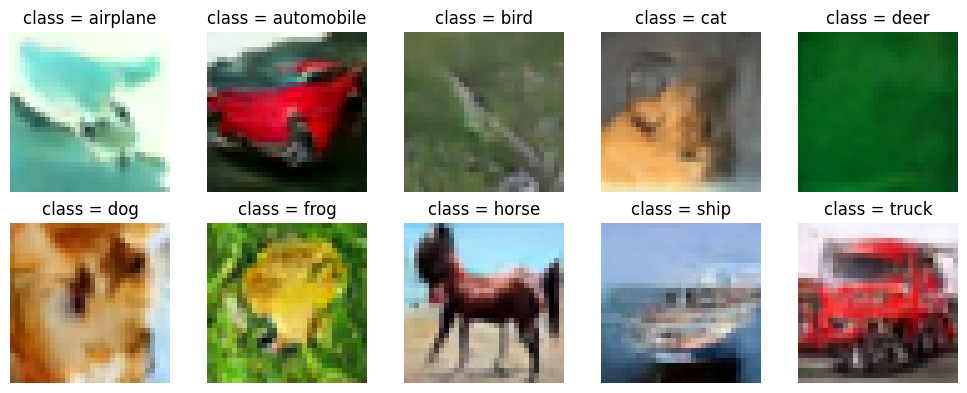

step: 3500, loss: 0.03149
Saved latest model at the current average loss: 0.03149
step: 4000, loss: 0.03153
Saved latest model at the current average loss: 0.03153
step: 4500, loss: 0.03108
Saved best model at best_loss: 0.03108
Saved latest model at the current average loss: 0.03108
step: 5000, loss: 0.03133
Saved latest model at the current average loss: 0.03133
step: 5500, loss: 0.03139
Saved latest model at the current average loss: 0.03139
step: 6000, loss: 0.03121
Saved latest model at the current average loss: 0.03121
Prediction at current step: 6000, avg_loss: 0.0292


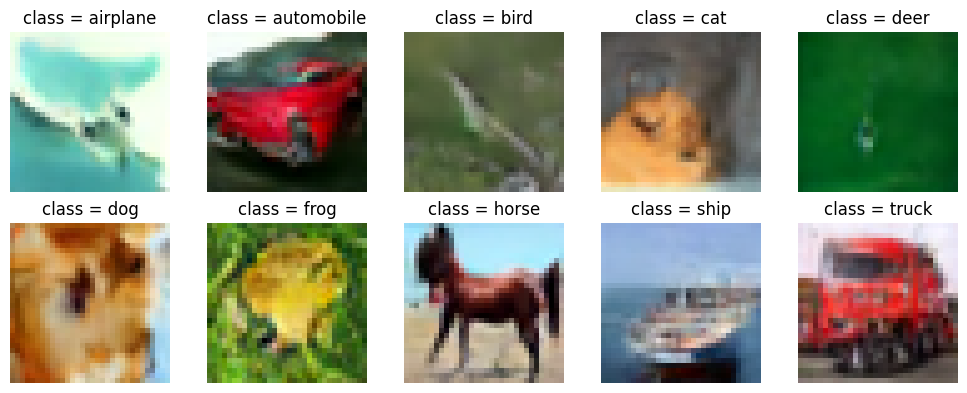

step: 6500, loss: 0.03119
Saved latest model at the current average loss: 0.03119
step: 7000, loss: 0.03114
Saved latest model at the current average loss: 0.03114
step: 7500, loss: 0.03165
Saved latest model at the current average loss: 0.03165
step: 8000, loss: 0.03073
Saved best model at best_loss: 0.03073
Saved latest model at the current average loss: 0.03073
step: 8500, loss: 0.03105
Saved latest model at the current average loss: 0.03105
step: 9000, loss: 0.03079
Saved latest model at the current average loss: 0.03079
Prediction at current step: 9000, avg_loss: 0.0293


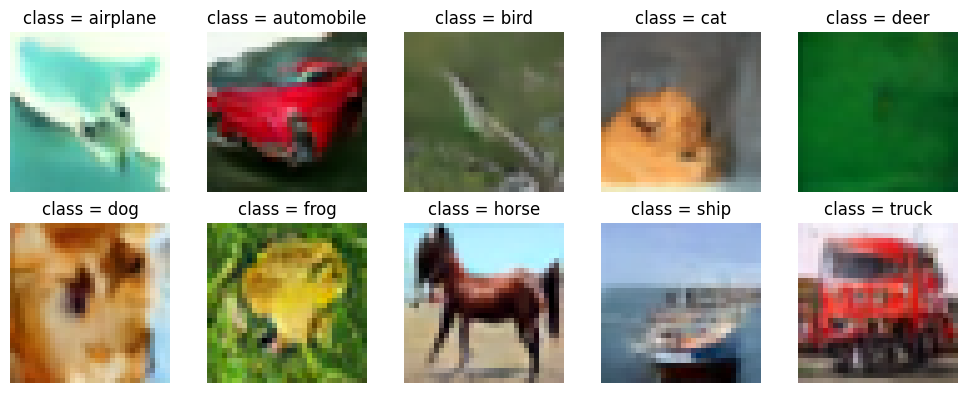

step: 9500, loss: 0.03113
Saved latest model at the current average loss: 0.03113
step: 10000, loss: 0.03110
Saved latest model at the current average loss: 0.03110
step: 10500, loss: 0.03074
Saved latest model at the current average loss: 0.03074
step: 11000, loss: 0.03078
Saved latest model at the current average loss: 0.03078
step: 11500, loss: 0.03079
Saved latest model at the current average loss: 0.03079
step: 12000, loss: 0.03093
Saved latest model at the current average loss: 0.03093
Prediction at current step: 12000, avg_loss: 0.0345


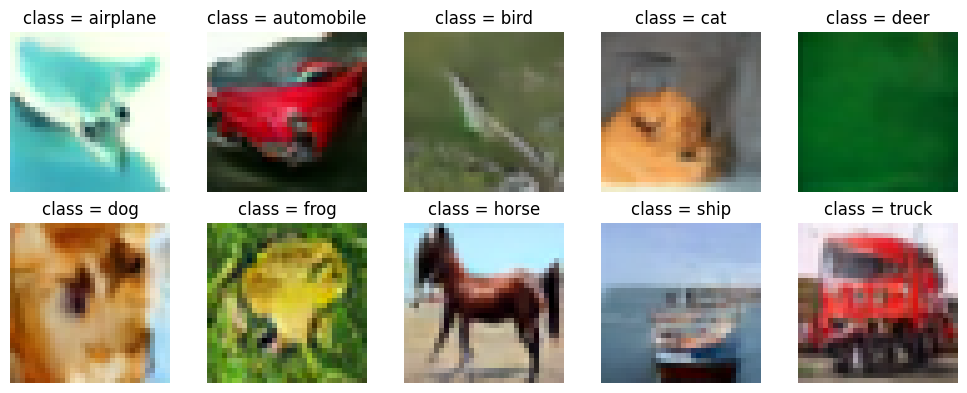

step: 12500, loss: 0.03081
Saved latest model at the current average loss: 0.03081
step: 13000, loss: 0.03069
Saved best model at best_loss: 0.03069
Saved latest model at the current average loss: 0.03069
step: 13500, loss: 0.03100
Saved latest model at the current average loss: 0.03100
step: 14000, loss: 0.03066
Saved best model at best_loss: 0.03066
Saved latest model at the current average loss: 0.03066
step: 14500, loss: 0.03054
Saved best model at best_loss: 0.03054
Saved latest model at the current average loss: 0.03054
step: 15000, loss: 0.03064
Saved latest model at the current average loss: 0.03064
Prediction at current step: 15000, avg_loss: 0.0271


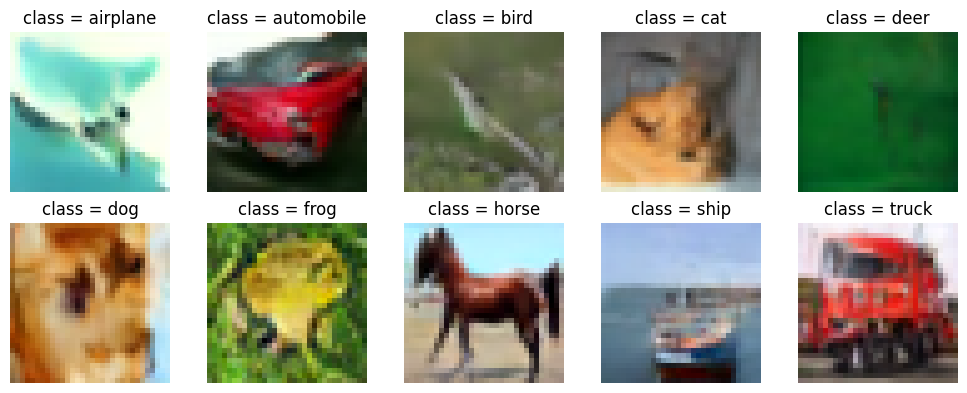

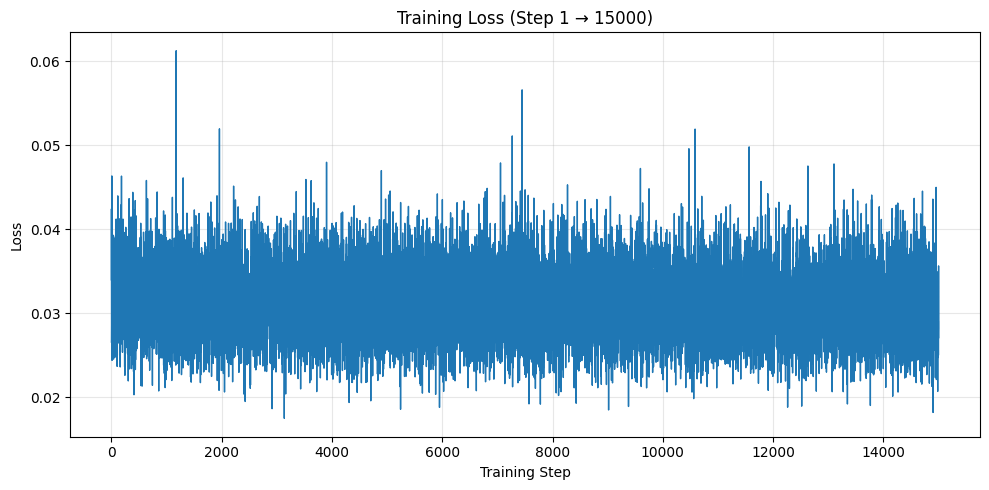

In [9]:
# Load from checkpoint
diffusion_pipeline.load_checkpoint(
    "diffusion_best.pt",
    # lr=1e-5
)

# # Just load the eval inputs: If model architecture changes.
# diffusion_pipeline.load_eval_inputs(
#     "diffusion_best.pt"
# )

# Training
epochs=1000
max_training_steps = 15000
lr=1e-4
log_step=500
prediction_step=3000


losses = diffusion_pipeline.train(
    epochs=epochs,
    max_training_steps=max_training_steps,
    lr=lr,
    log_step=log_step,
    prediction_step=prediction_step
)

## Training performance snapshot

Both runs executed **15,000 run-local steps**. The saved `training.csv` files record elapsed time at each run's final logged step:

| Run | Steps executed in this run | Final logged elapsed time | Best 500-step average loss |
|---|---:|---:|---:|
| v65 | 15,000 | 6,169 s (1.71 h) | 0.03161 at run-local step 14,000 |
| v66 | 15,000 | 6,055 s (1.68 h) | 0.03054 at run-local step 14,500 |

The notebook's broader wall-clock measurements print **1.73 h for v65** and **1.70 h for v66**. The v66 output below also prints **4.74 steps/sec** and **1,208.74 images/sec**, but those rates divide cumulative checkpoint counters by v66's run time. They are not run-local throughput. Using v66's run-local image count and final CSV time gives approximately **632 images/sec**.

The recorded v66 resource snapshot also includes **2.93 GB peak GPU allocated**, **4.01 GB peak GPU reserved**, and **18.59 GB process RAM**.

### v65 Training Loss

The original saved v65 plot covers its own steps 1–15,000. The image is embedded in this markdown cell.

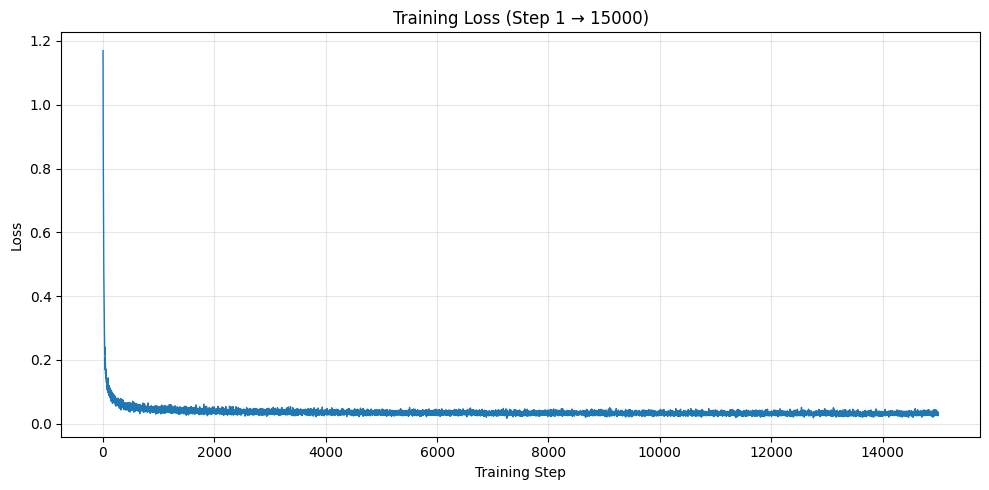

### v66 Training Loss

The original saved v66 plot also uses run-local steps 1–15,000. It is shown here for comparison and remains unchanged in the training cell's captured output above.

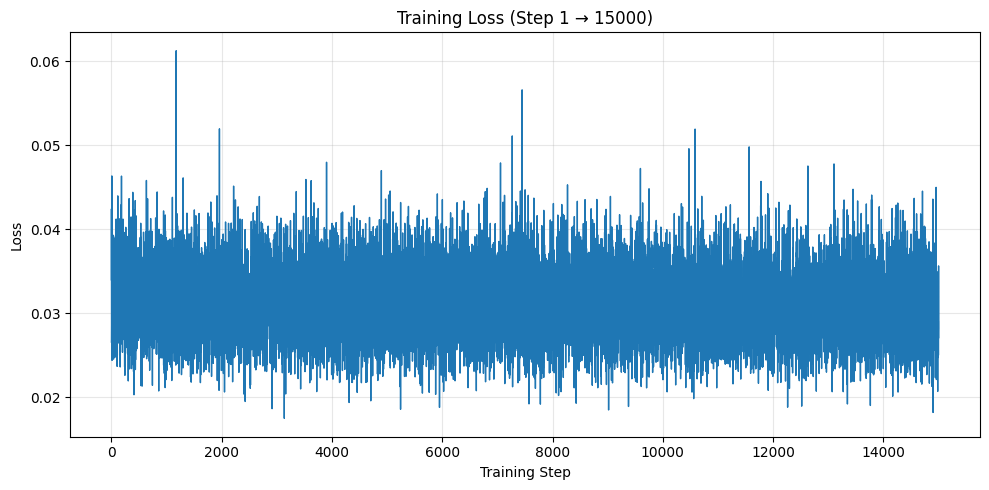


In [10]:
# Resource logging after training
training_time = time.time() - training_start_time

print(f"Training time: {training_time / 3600:.2f} hours")

if diffusion_pipeline.metadata["total_training_steps"] > 0:
    steps_per_second = (
        diffusion_pipeline.metadata["total_training_steps"]
        / training_time
    )

    images_per_second = (
        diffusion_pipeline.metadata["total_data_processed"]
        / training_time
    )

    print(f"Steps/sec: {steps_per_second:.2f}")
    print(f"Images/sec: {images_per_second:.2f}")

if torch.cuda.is_available():
    peak_allocated = torch.cuda.max_memory_allocated() / 1024**3
    peak_reserved = torch.cuda.max_memory_reserved() / 1024**3

    print(f"Peak GPU memory allocated: {peak_allocated:.2f} GB")
    print(f"Peak GPU memory reserved: {peak_reserved:.2f} GB")

process_ram = process.memory_info().rss / 1024**3
print(f"Process RAM: {process_ram:.2f} GB")


Training time: 1.70 hours
Steps/sec: 4.74
Images/sec: 1208.74
Peak GPU memory allocated: 2.93 GB
Peak GPU memory reserved: 4.01 GB
Process RAM: 18.59 GB


In [11]:
# # Sampling
# labels = torch.randint(0, 10, (16,), device=device)

# x_pred_sample = diffusion_pipeline.predict(
#     labels=labels,
#     guidance_scale=1.5
# )


# # Plot
# diffusion_pipeline.plot_batch(
#     x_pred_sample[:10],
#     labels[:10]
# )

# Notebook Cleanup

The dataset cache is removed after training to keep the working environment smaller.

This does **not** remove the trained model or the captured notebook outputs. The important artifacts are the checkpoints, logs, plots, and the notebook itself.

# Notebook Cleanup

In [12]:
import shutil

data_folder = "./data"
shutil.rmtree(data_folder)
print(f"Data filder: '{data_folder}' removed for cleanup")

Data filder: './data' removed for cleanup


# Predictions and Evaluation

This section evaluates the trained model under controlled sampling conditions.

A fixed initial noise tensor is created once and reused. The labels are:

```text
0 → airplane
1 → automobile
2 → bird
3 → cat
4 → deer
5 → dog
6 → frog
7 → horse
8 → ship
9 → truck
```

Using fixed noise is important for visual comparison because changes in generated images are then primarily attributable to the model or sampling configuration rather than a completely different random starting point.

# Predictions

In [13]:
_ = torch.manual_seed(42)

initial_noise = torch.randn(
    10, 3, 32, 32,
    device=device
)

labels = torch.arange(10, device=device)

## Classifier-Free Guidance (CFG)

The model performs two predictions for each reverse-diffusion step:

1. **Unconditional**
   $$
   \epsilon_{\text{uncond}}
   =
   \epsilon_\theta(x_t,t,\varnothing)
   $$

2. **Conditional**
   $$
   \epsilon_{\text{cond}}
   =
   \epsilon_\theta(x_t,t,y)
   $$

They are combined as:

$$
\boxed{
\epsilon_{\text{CFG}}
=
\epsilon_{\text{uncond}}
+
s
\left(
\epsilon_{\text{cond}}
-
\epsilon_{\text{uncond}}
\right)
}
$$

where `s` is the guidance scale.

### Intuition

- `s = 0`: unconditional generation
- `s = 1`: ordinary conditional prediction
- moderate `s`: stronger class adherence
- very large `s`: stronger conditioning but potentially reduced diversity or unnatural artifacts

This notebook explicitly compares:

$$
s \in \{0,1,2,3,5,7\}
$$

using the **same initial noise** for every value.

The captured results show that the model has learned recognizable CIFAR-10 class structure. At this resolution, the images are intentionally interpreted as **32×32 diffusion samples**, not as photorealistic images.

Model loaded successfully from checkpoint: diffusion_best.pt
Best Loss: 0.0305
Metadata: {'total_epochs': 0, 'total_training_steps': 28500, 'total_data_processed': 7270656, 'conditioning': 'one_hot', 'num_classes': 10, 'null_class': 10, 'model_parameters': 6767683}
guidance_scale: 0.0


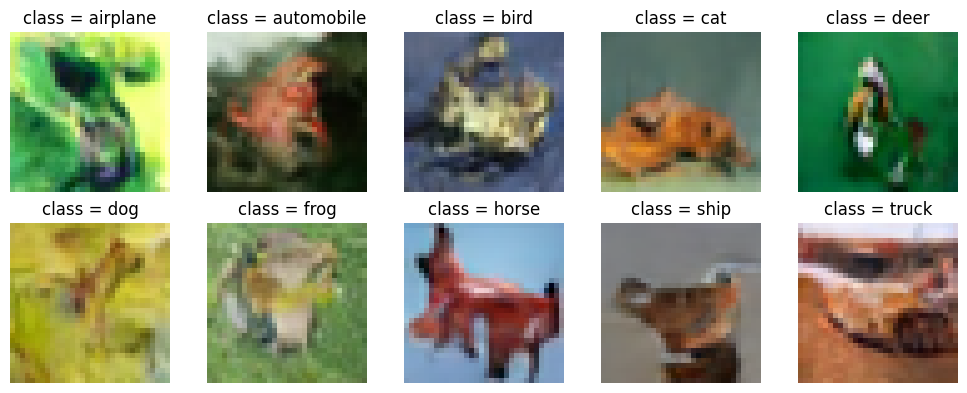

guidance_scale: 1.0


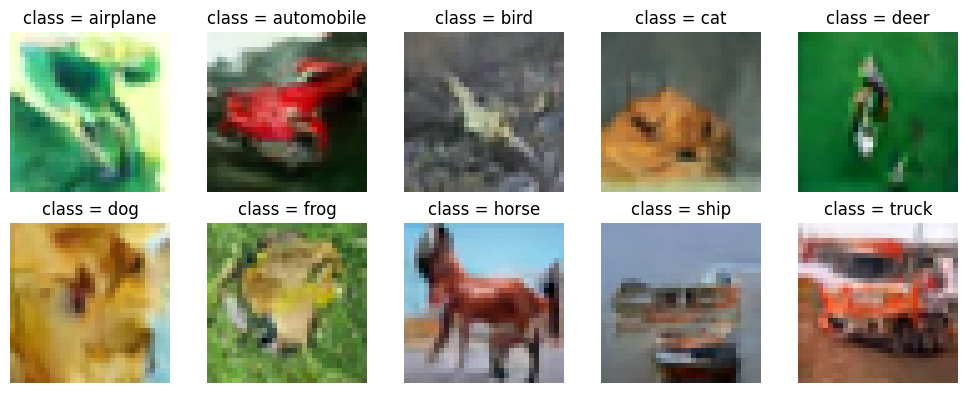

guidance_scale: 2.0


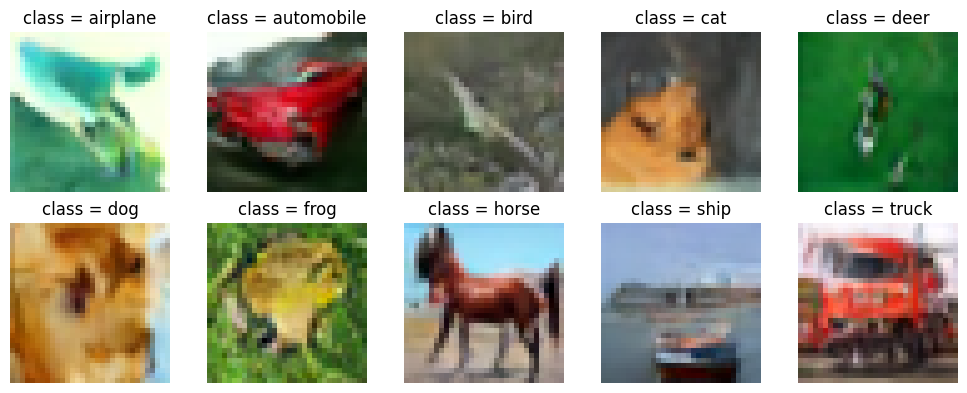

guidance_scale: 3.0


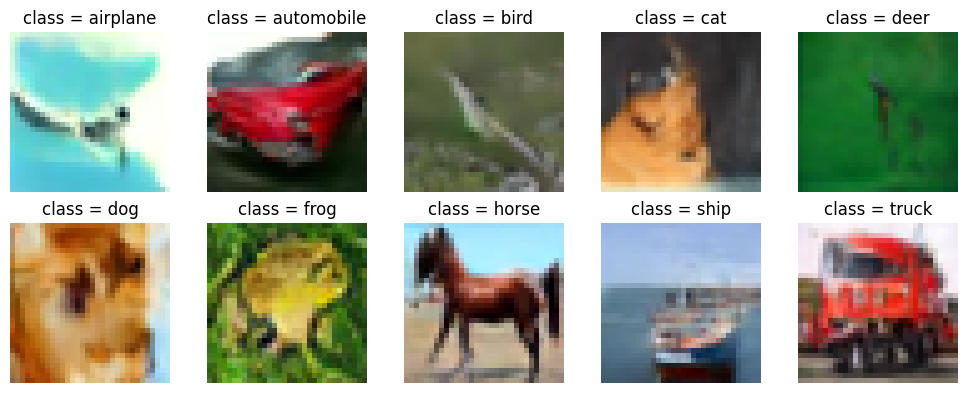

guidance_scale: 5.0


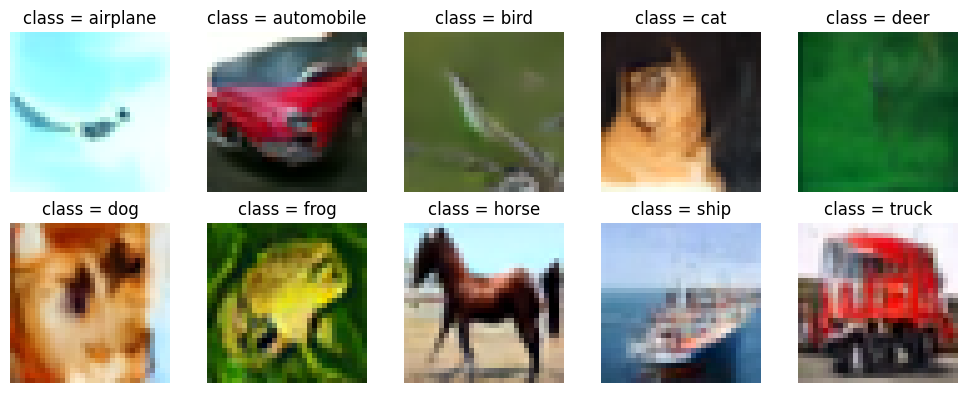

guidance_scale: 7.0


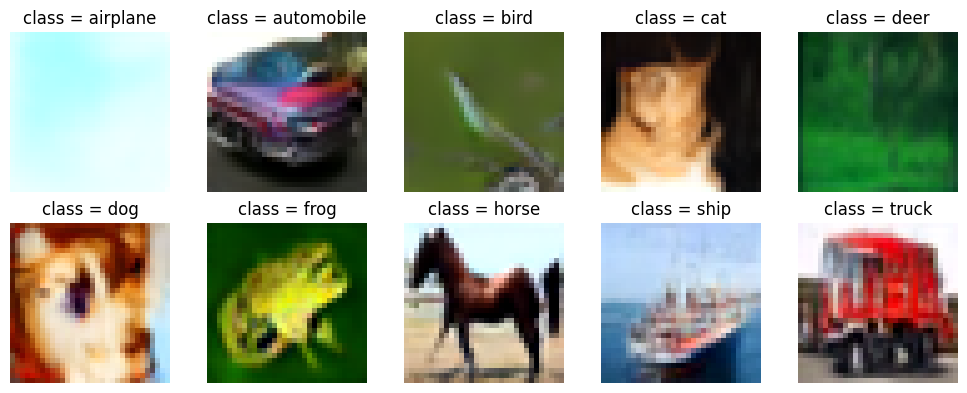

In [14]:
diffusion_pipeline.load_checkpoint("diffusion_best.pt")


guidance_scales = [0.0, 1.0, 2.0, 3.0, 5.0, 7.0]
for guidance_scale in guidance_scales:
    print(f"guidance_scale: {guidance_scale}")
    samples = diffusion_pipeline.predict(
        xt=initial_noise,
        labels=labels,
        guidance_scale=guidance_scale,
        deterministic=True
    )

    diffusion_pipeline.plot_batch(
        samples,
        labels,
        save_path=f"samples/cfg_comparison/cfg_{guidance_scale:.1f}.png"
    )

### Test Start

The following checks are intentionally small and transparent. They inspect the relationship between the true noise used in the forward process and the noise predicted by the trained model.

### Test Start

## Sanity check: forward diffusion and noise prediction

For a batch of real CIFAR-10 images, this cell:

1. samples random diffusion timesteps
2. samples Gaussian noise
3. constructs `x_t` using the forward equation
4. asks the model to predict the noise
5. compares simple statistics of the true and predicted noise

The expected qualitative behavior is not that the means and standard deviations must be identical. Rather, this is a lightweight diagnostic that confirms the model is operating in the intended noise-prediction setup.

The important training objective remains the MSE between the full predicted and true noise tensors.

In [15]:
images, labels = next(iter(data_loader))
images = images.to(device)
labels = labels.to(device)

B = images.shape[0]
timesteps = diffusion_pipeline.timesteps
alphas_bar = diffusion_pipeline.alphas_bar
betas_bar = diffusion_pipeline.betas_bar


t = torch.randint(
    0, timesteps, (B,),
    device=device
).float()

noise = torch.randn_like(images)

alpha_bar_t = alphas_bar[t.long()].to(device)
beta_bar_t = betas_bar[t.long()].to(device)

xt = (
    torch.sqrt(alpha_bar_t)[:, None, None, None] * images
    + torch.sqrt(beta_bar_t)[:, None, None, None] * noise
)

with torch.no_grad():
    pred = model(xt, t, labels)

print("True noise:")
print(" mean:", noise.mean().item())
print(" std :", noise.std().item())

print("Predicted noise:")
print(" mean:", pred.mean().item())
print(" std :", pred.std().item())

True noise:
 mean: 0.002169145504012704
 std : 0.9991649389266968
Predicted noise:
 mean: -0.0020299642346799374
 std : 0.9908043742179871


## Mixed class conditioning

One of the useful properties of using an explicit **one-hot class vector** is that the conditioning representation can be manipulated directly.

For example:

$$
c_{\text{dog}} =
[0,0,0,0,0,1,0,0,0,0,0]
$$

and

$$
c_{\text{cat}} =
[0,0,0,1,0,0,0,0,0,0,0]
$$

A 50/50 mixture is:

$$
c_{\text{mix}}
=
0.5c_{\text{dog}}
+
0.5c_{\text{cat}}
$$

The resulting vector is passed through the same class-conditioning MLP used during ordinary generation.

### What this demonstrates

The experiment tests several mixtures:

- 50% dog + 50% cat
- 50% cat + 50% bird
- 50% dog + 50% horse
- 50% automobile + 50% bird
- 50% bird + 50% frog
- 50% airplane + 50% ship

The results are **not expected to behave like a mathematically exact image interpolation**. The conditioning space was trained on discrete classes, so these vectors are an experiment outside the standard training labels.

Nevertheless, the samples show that the model can respond to continuous combinations of class-conditioning directions. This is a particularly useful demonstration of why exposing the conditioning vector explicitly is more flexible than hard-coding only integer labels.

### Example data flow

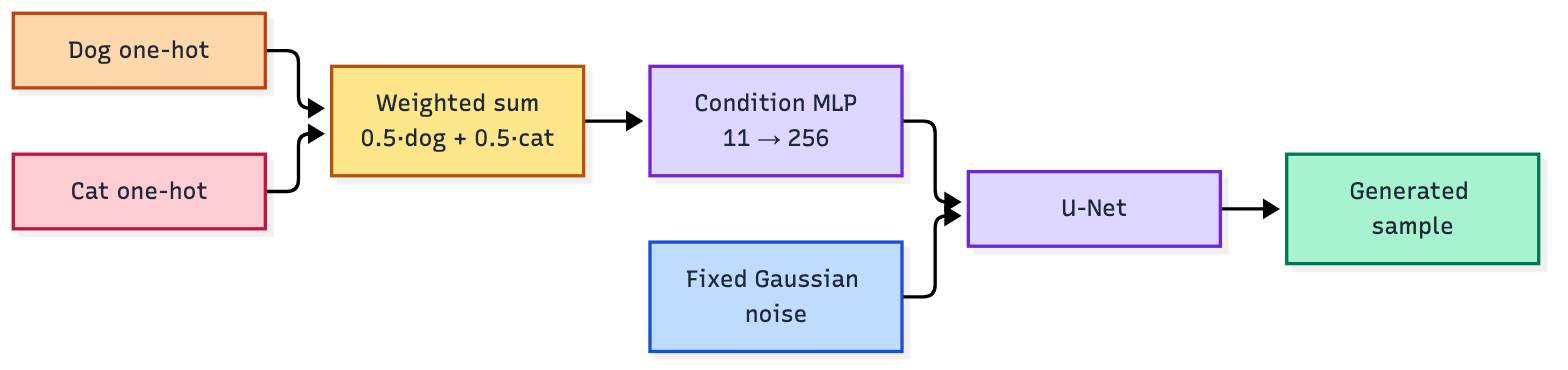

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart LR
    D["Dog one-hot"] --> M["Weighted sum<br/>0.5·dog + 0.5·cat"]
    C["Cat one-hot"] --> M
    M --> E["Condition MLP<br/>11 → 256"]
    E --> U["U-Net"]
    N["Fixed Gaussian noise"] --> U
    U --> S["Generated sample"]
    classDef dog fill:#fed7aa,stroke:#c2410c,color:#1f2937
    classDef cat fill:#fecdd3,stroke:#be123c,color:#1f2937
    classDef blend fill:#fde68a,stroke:#b45309,color:#1f2937
    classDef model fill:#ddd6fe,stroke:#6d28d9,color:#1f2937
    classDef sample fill:#a7f3d0,stroke:#047857,color:#1f2937
    classDef noise fill:#bfdbfe,stroke:#1d4ed8,color:#1f2937
    class D dog
    class C cat
    class M blend
    class E,U model
    class N noise
    class S sample
```

</details>

best_loss: 0.03054


Text(0.5, 0.98, 'Mixed Conditioning Samples')

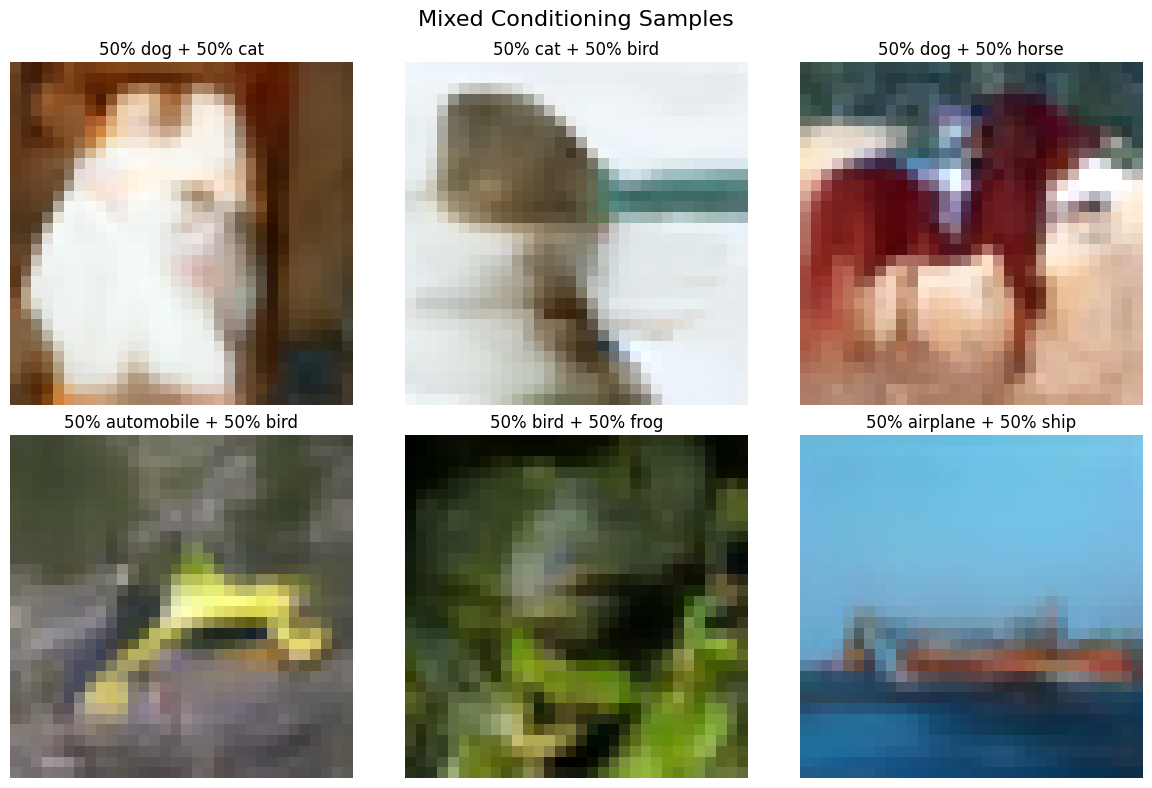

In [16]:
print(f"best_loss: {diffusion_pipeline.best_loss:.5f}")

# ------------------------------------------------------------
# Multiple mixed-conditioning combinations
# ------------------------------------------------------------
class_names = diffusion_pipeline.class_names

combinations = [
    (["dog", "cat"], [0.5, 0.5]),
    (["cat", "bird"], [0.5, 0.5]),
    (["dog", "horse"], [0.5, 0.5]),
    (["automobile", "bird"], [0.5, 0.5]),
    (["bird", "frog"], [0.5, 0.5]),
    (["airplane", "ship"], [0.5, 0.5]),
]

mixed_vectors = []
titles = []

for names, weights in combinations:
    vector = torch.zeros(11, device=device)

    for name, weight in zip(names, weights):
        label_idx = class_names.index(name)
        vector[label_idx] = weight

    mixed_vectors.append(vector)
    titles.append(" + ".join(
        f"{w*100:.0f}% {n}" for n, w in zip(names, weights)
    ))

mixed_vectors = torch.stack(mixed_vectors)

# One fixed noise image per combination
mixed_noise = initial_noise[:len(combinations)]

mixed_samples = diffusion_pipeline.predict(
    xt=mixed_noise,
    labels=torch.zeros(len(combinations), dtype=torch.long, device=device),
    label_vector=mixed_vectors,
    guidance_scale=3.0,
    deterministic=True
)

# ------------------------------------------------------------
# Custom plot
# ------------------------------------------------------------
imgs = ((mixed_samples.detach().cpu() + 1) / 2).clip(0, 1)

fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 8)
)

for i, ax in enumerate(axes.flat):
    _  = ax.imshow(imgs[i].permute(1, 2, 0))
    _ = ax.set_title(titles[i])
    _ = ax.axis("off")

plt.suptitle("Mixed Conditioning Samples", fontsize=16)
plt.tight_layout()
plt.show()
plt.close(fig)

### Test End

## Final takeaway

This notebook demonstrates a complete, from-scratch conditional DDPM rather than only a model definition.

The most important engineering and ML pieces are all visible:

- mathematical forward diffusion
- learned denoising objective
- conditional U-Net
- residual connections
- multi-resolution self-attention
- timestep and class conditioning
- classifier-free training
- EMA stabilization
- checkpoint persistence
- reproducible sampling
- CFG comparison
- mixed conditioning
- resource/performance measurement

### Result quality

The generated 32×32 samples are clearly more structured than random noise and capture recognizable CIFAR-10 object categories. The model is still intentionally compact, so the output should be judged as a **successful learning implementation and engineering project**, not as a state-of-the-art image generator.

### How to discuss this project in an interview

A concise description is:

> **Built a 6.8M-parameter class-conditional DDPM from scratch in PyTorch on CIFAR-10, implementing a U-Net with residual blocks, multi-resolution self-attention, timestep/class conditioning, EMA, classifier-free guidance, reproducible sampling, and continuous mixed-label conditioning.**

The interesting part of the project is not only the final images. It is that the notebook exposes the complete mathematical and engineering path from:

$$
x_0
\rightarrow
x_t
\rightarrow
\epsilon_\theta
\rightarrow
\hat{x}_0
\rightarrow
x_{t-1}
\rightarrow
\text{generated image}
$$

with the corresponding implementation and experimental evidence.

### Test End